# Análisis exploratorio · percentil de precio del día
**Grupo 5K10-13 · Mercado de skins de Counter-Strike 2 · Ciencia de Datos · UTN FRM 2026**

---

## La pregunta

> **¿Se puede estimar, sólo con sus atributos, en qué percentil de precio va a
> quedar un skin recién lanzado?**

Percentil 90 quiere decir que ese skin es más caro que el 90 % del mercado ese día.

## Las decisiones de las que parte este notebook

| # | Decisión | En qué sección se ve |
|---|---|---|
| 1 | Objetivo: **percentil del precio dentro del día** (0 a 100), con regresión | 3 y 4 |
| 2 | Uso del modelo: **skins nuevos**, que todavía no tienen precio estable | 9 |
| 3 | El percentil **se pasa a dólares** con la distribución de precios del día | 3 |
| 4 | Validación como uso real: **colecciones viejas para entrenar, nuevas para probar** | 9 |
| 5 | Comparar modelos de menor a mayor, empezando por una línea de base | 9 (sólo la base) |
| 6 | Sólo armas, sin cuchillos ni guantes | 2 |

## Cómo está organizado

| Sección | Qué hay |
|---|---|
| 0 | Qué cambió y lo que nos marcaron |
| 1 | Carga de uno o varios snapshots |
| 2 | El perfil: los números que pide la consigna, con la asimetría de todas las numéricas |
| 3 | La variable objetivo: del precio al percentil, y de vuelta a dólares |
| 4 | Estabilidad del percentil entre fechas (si hay más de un snapshot) |
| 5 | Medidas, semáforo y fichas |
| 6 | Las cuatro hipótesis |
| 7 | La tabla de columnas candidatas |
| 8 | Cierre: fichas, respuestas obligatorias y exportación |
| 9 | Puente a la Entrega 3: la validación temporal y la línea de base |

Las celdas marcadas con **✍** son las únicas que hay que editar a mano.

## 0 · Qué cambió · Lo que nos marcaron ✍

Es lo que se dice en los minutos 0 a 2 de la defensa.
✍ Revisar que la primera columna use las palabras de la cátedra.

### Entrega 1 → pipeline

| Lo que nos marcaron | Qué cambiamos | Dónde se ve |
|---|---|---|
| No sabíamos de qué colección salía cada skin | `collection` se cruza **por `skin_id`** con `collections.json` y `crates.json`, no por nombre. Cobertura 99,93 %, una sola colección por skin | Pipeline, T3 · columna `collection` |
| Faltaba una medida de la escasez | `p_item` y `neg_log_p_item`: la probabilidad de que un drop sea ese item exacto, con las odds oficiales aplicadas por peldaño de la colección | Pipeline, T3 · H4 |
| Las souvenir no tenían lugar en el análisis | Columna `origen`: caja, paquete souvenir, drop de mapa o sin identificar. Suma las souvenir sin inventarles probabilidades | Pipeline, T3 · sección 2.5 |
| La fecha del snapshot salía corrida un día | `_snapshot()` usa el momento en que arrancó la corrida, en hora argentina, y no el `logical_date` | Pipeline · columna `fecha_snapshot` |
| Si el cruce con el catálogo fallaba, se publicaba igual | La corrida termina en rojo si menos del 95 % de las filas tiene colección | Pipeline, T5 `unir_y_validar` |

### Entrega 2 → este notebook

| Lo que nos marcaron | Qué cambiamos | Dónde se ve |
|---|---|---|
| El objetivo eran bandas de precio | El objetivo es el **percentil del precio dentro del día** (regresión, 0 a 100). Se pasa a dólares con la distribución del día | Secciones 3 y 4 |
| Las cuatro hipótesis daban amarillo porque comparaban skins distintos | Comparaciones **en pares**: el mismo skin en versión souvenir y normal (H2) y el mismo skin en distintos exteriores (H3) | Sección 6 |

### Además, en esta versión

- Asimetría de **todas** las numéricas, no sólo la del precio (2.6).
- Gráfico de estabilidad del percentil entre fechas (4).
- La traducción a dólares usa el error real de la línea de base, no 4 puntos (3.3).
- H1 se compara contra lo que da el azar; H4 tiene su gráfico (6).
- La tabla de candidatas dice qué mide cada columna y en qué zona quedó (7).

## 1 · Carga de datos

El notebook lee **todos** los snapshots que encuentre en la carpeta. El análisis
se hace sobre el más reciente; los demás se usan sólo en la sección 4, para
mostrar que el percentil se mantiene estable entre fechas.

In [1]:
import json
import math
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 110

# En Colab se monta el Drive; en una compu local se usa la carpeta include/.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/include")
except ImportError:
    BASE = Path("include")

SALIDAS = BASE / "entrega2"
SALIDAS.mkdir(parents=True, exist_ok=True)
print("carpeta de datos:", BASE)

Mounted at /content/drive
carpeta de datos: /content/drive/MyDrive/include


In [2]:
# Las cuatro columnas de fecha del pipeline. Las CUATRO tienen que ir en
# parse_dates: si falta una, vuelve como texto y las restas de fechas fallan.
COLUMNAS_FECHA = ["fecha_snapshot", "captured_at", "collection_release",
                  "caja_fecha"]

archivos = sorted(p for p in BASE.glob("cs2_skins_dataset_*.csv")
                  if not p.stem.endswith("_excel"))
if not archivos:
    raise FileNotFoundError(f"No hay CSV del pipeline en {BASE}")

partes = []
for ruta in archivos:
    parte = pd.read_csv(ruta)
    fechas = [c for c in COLUMNAS_FECHA if c in parte.columns]
    for c in fechas:
        parte[c] = pd.to_datetime(parte[c], errors="coerce")
    partes.append(parte)
df_todo = pd.concat(partes, ignore_index=True)

fechas_disponibles = sorted(df_todo["fecha_snapshot"].dt.date.unique())
SNAPSHOT = str(fechas_disponibles[-1])
print("snapshots encontrados:", [str(f) for f in fechas_disponibles])
print("se analiza el más reciente:", SNAPSHOT)

snapshots encontrados: ['2026-09-24', '2026-10-15']
se analiza el más reciente: 2026-10-15


### Normalizaciones y la variable objetivo

Tres cosas antes de empezar:

- Los booleanos vuelven del CSV como `object` cuando tienen nulos, y en una
  columna `object` el operador `~` devuelve enteros en vez de un booleano. Se
  normalizan acá para que los filtros no fallen sin avisar.
- **`percentil_precio`**: la posición de cada skin dentro del mercado **de su
  día**. Se calcula agrupando por fecha, así cada snapshot tiene su propio 0-100.
- **`origen`**: de dónde sale el item. Si el pipeline ya la trae, se usa; si
  no, se reconstruye una versión simplificada con las columnas que hay.

In [3]:
for col in ("caja_discontinuada", "stattrak", "souvenir"):
    if col in df_todo.columns:
        df_todo[col] = (df_todo[col].map({True: True, False: False,
                                          "True": True, "False": False})
                        .astype("boolean"))

df_todo["log_precio"] = np.log10(df_todo["sell_price_usd"])

# percentil del día: cada snapshot tiene su propio 0-100
df_todo["percentil_precio"] = (df_todo.groupby("fecha_snapshot")["sell_price_usd"]
                               .rank(pct=True) * 100)

if "origen" not in df_todo.columns:
    df_todo["origen"] = np.select(
        [df_todo["souvenir"].fillna(False).astype(bool),
         df_todo["caja"].notna()],
        ["souvenir", "caja"], default="drop de mapa")
    print("AVISO: 'origen' reconstruida en el notebook (versión simplificada)")

df = df_todo[df_todo["fecha_snapshot"].dt.date.astype(str) == SNAPSHOT].copy()
if "antiguedad_col_dias" not in df.columns or df["antiguedad_col_dias"].isna().all():
    df["antiguedad_col_dias"] = (df["fecha_snapshot"] - df["collection_release"]).dt.days

print(f"snapshot {SNAPSHOT}: {df.shape[0]} filas x {df.shape[1]} columnas")

snapshot 2026-10-15: 2012 filas x 31 columnas


In [4]:
COLUMNAS_ESPERADAS = [
    "market_hash_name", "skin_id", "weapon", "category_name", "rarity", "wear",
    "wear_orden", "rarity_orden", "stattrak", "souvenir", "collection",
    "collection_release", "caja", "neg_log_p_item", "sell_price_usd",
    "sell_listings", "fecha_snapshot",
]
faltan = [c for c in COLUMNAS_ESPERADAS if c not in df.columns]
print("columnas faltantes:", faltan if faltan else "ninguna")

for c in ("collection_release", "caja_fecha"):
    if c in df.columns:
        ok = pd.api.types.is_datetime64_any_dtype(df[c])
        print(f"{c:20s} {'OK, es fecha' if ok else 'ATENCIÓN: no quedó como fecha'}")

columnas faltantes: ninguna
collection_release   OK, es fecha
caja_fecha           OK, es fecha


## 2 · El perfil del dataset

### 2.1 · Tamaño, unidad de análisis y alcance

In [5]:
print("filas, columnas:", df.shape)
print("una fila es: un skin de arma de CS2 identificado por su market_hash_name")
print("-arma, patrón, exterior, StatTrak o Souvenir-, observado el", SNAPSHOT)
print("ejemplo:", df["market_hash_name"].iloc[0])
print()
print("categorías presentes:", sorted(df["category_name"].dropna().unique()))
print("Sólo armas: sin cuchillos ni guantes (decisión 6).")

filas, columnas: (2012, 31)
una fila es: un skin de arma de CS2 identificado por su market_hash_name
-arma, patrón, exterior, StatTrak o Souvenir-, observado el 2026-10-15
ejemplo: StatTrak™ AK-47 | The Oligarch (Minimal Wear)

categorías presentes: ['Heavy', 'Pistols', 'Rifles', 'SMGs']
Sólo armas: sin cuchillos ni guantes (decisión 6).


### 2.2 · Tipos

In [6]:
print(df.dtypes.value_counts().to_string())

float64           11
object            10
datetime64[ns]     4
boolean            3
int64              3


### 2.3 · Nulos, y de qué tipo son

La consigna no pide cero nulos: pide distinguir los **faltantes de verdad** de
los **estructurales**, que son los que tienen que estar vacíos.

In [7]:
TIPO_DE_NULO = {
    "p_item": ("estructural", "sólo existe para items que salen de una caja"),
    "p_rareza": ("estructural", "idem p_item"),
    "neg_log_p_item": ("estructural", "idem p_item"),
    "caja": ("estructural", "las colecciones de mapa y souvenir no tienen caja"),
    "caja_fecha": ("estructural", "idem caja"),
    "caja_discontinuada": ("estructural", "idem caja"),
    "collection": ("faltante real", "el catálogo no ubica algunas armas en una colección"),
    "collection_release": ("faltante real", "el catálogo no publica la fecha de lanzamiento de algunas colecciones"),
    "antiguedad_col_dias": ("faltante real", "depende de collection_release"),
    "min_float": ("faltante real", "el catálogo no cubre todos los skins"),
    "max_float": ("faltante real", "idem min_float"),
    "p_wear": ("faltante real", "depende de min_float y max_float"),
}
nulos = df.isna().mean().sort_values(ascending=False)
tabla_nulos = pd.DataFrame([
    {"columna": c, "% nulos": round(p * 100, 2),
     "tipo": TIPO_DE_NULO.get(c, ("SIN CLASIFICAR", ""))[0],
     "por qué": TIPO_DE_NULO.get(c, ("", "revisar"))[1]}
    for c, p in nulos[nulos > 0].items()])
print("nulos en el precio:", int(df["sell_price_usd"].isna().sum()),
      "- el inner join y el filtro de precios <= 0 los sacan antes")
tabla_nulos

nulos en el precio: 0 - el inner join y el filtro de precios <= 0 los sacan antes


,columna,% nulos,tipo,por qué
0,p_item,51.64,estructural,sólo existe para items que salen de una caja
1,neg_log_p_item,51.64,estructural,idem p_item
2,caja,48.91,estructural,las colecciones de mapa y souvenir no tienen caja
3,caja_fecha,48.91,estructural,idem caja
4,caja_discontinuada,48.91,estructural,idem caja
5,antiguedad_col_dias,0.40,faltante real,depende de collection_release
6,collection_release,0.40,faltante real,el catálogo no publica la fecha de lanzamiento de algunas colecciones


Los nulos estructurales de `neg_log_p_item` **no se borran**. En la
Entrega 3 van con `SimpleImputer(add_indicator=True)` dentro del `Pipeline`: se
completa el valor y se agrega una columna que dice "este item no sale de una
caja". El modelo aprende de esa señal en vez de perder esas filas.

### 2.4 · Constantes, duplicados y filas hermanas

In [8]:
constantes = list(df.columns[df.nunique() <= 1])
print("constantes:", constantes if constantes else "ninguna")
print("  (fecha_snapshot y captured_at lo son por construcción: es un corte de un día)")
print()
print("duplicados de market_hash_name:", int(df["market_hash_name"].duplicated().sum()))
print()
por_skin = df.groupby("skin_id").size()
print("skins base distintos :", len(por_skin))
print("filas por skin base  : mediana", por_skin.median(), "| máximo", por_skin.max())
print("colecciones          :", df["collection"].nunique())
print("armas distintas      :", df["weapon"].nunique())
print()
print("El mismo skin base genera varias filas (exteriores, StatTrak, Souvenir).")
print("Son 'filas hermanas': por eso la validación agrupa por colección.")

constantes: ['fecha_snapshot', 'captured_at']
  (fecha_snapshot y captured_at lo son por construcción: es un corte de un día)

duplicados de market_hash_name: 0

skins base distintos : 563
filas por skin base  : mediana 4.0 | máximo 10
colecciones          : 93
armas distintas      : 34

El mismo skin base genera varias filas (exteriores, StatTrak, Souvenir).
Son 'filas hermanas': por eso la validación agrupa por colección.


### 2.5 · De dónde sale cada item

In [9]:
print(df["origen"].value_counts(normalize=True).mul(100).round(1).to_string())

origen
caja                48.4
drop de mapa        30.3
paquete souvenir    12.8
sin identificar      8.5


Las variantes que el catálogo genera pero nadie vende —por ejemplo
"Souvenir" de skins que en el juego no la tienen— **no llegan acá**: el inner
join con Steam las deja afuera, porque sin un listado en el mercado no tienen
precio.

### 2.6 · Asimetría de todas las numéricas

La regla: con |asimetría| > 1 la columna se transformaría (logaritmo); entre 0,5
y 1 se mira; por debajo, se deja como está. La última columna dice qué se hace
con cada una, porque varias ni siquiera entran al modelo.

In [10]:
QUE_SE_HACE = {
    "sell_price_usd": "no es feature: de acá sale el objetivo, que es el percentil",
    "log_precio": "es el log del precio: muestra cuánto corrige la transformación",
    "percentil_precio": "es el objetivo: parejo por construcción",
    "sell_listings": "no entra: fuga (sección 7)",
    "p_item": "ya se usa transformada: el modelo ve neg_log_p_item",
    "neg_log_p_item": "entra como secundaria (H4): ya es un logaritmo",
    "p_rareza": "no entra: está dentro de neg_log_p_item",
    "n_skins_rareza_col": "no entra: está dentro de neg_log_p_item",
    "p_wear": "no entra: supuesto parcialmente validado",
    "antiguedad_col_dias": "no entra: para un skin nuevo vale ~0 (sección 7)",
    "wear_orden": "ordinal: entra como número, sin transformar",
    "rarity_orden": "ordinal: sus escalones ya son el log de la escasez",
    "min_float": "no entra al modelo",
    "max_float": "no entra al modelo",
}

numericas = df.select_dtypes("number")
numericas = numericas[[c for c in numericas.columns
                       if not pd.api.types.is_bool_dtype(numericas[c])
                       and numericas[c].nunique() > 2]]
asimetria = numericas.skew().sort_values(key=abs, ascending=False)


def regla_asimetria(valor):
    v = abs(valor)
    return "transformar (log)" if v > 1 else "mirar" if v > 0.5 else "dejar"


tabla_asimetria = pd.DataFrame({
    "columna": asimetria.index,
    "asimetría": asimetria.round(2).values,
    "regla": [regla_asimetria(v) for v in asimetria],
    "qué se hace": [QUE_SE_HACE.get(c, "revisar") for c in asimetria.index],
})
a_transformar = tabla_asimetria.loc[tabla_asimetria["regla"] == "transformar (log)", "columna"]
print("se transformarían (|asimetría| > 1):", list(a_transformar) or "ninguna")
tabla_asimetria

se transformarían (|asimetría| > 1): ['sell_listings', 'sell_price_usd', 'min_float', 'p_item', 'p_wear']


,columna,asimetría,regla,qué se hace
0,sell_listings,19.36,transformar (log),no entra: fuga (sección 7)
1,sell_price_usd,5.85,transformar (log),"no es feature: de acá sale el objetivo, que es el percentil"
2,min_float,3.65,transformar (log),no entra al modelo
3,p_item,3.33,transformar (log),ya se usa transformada: el modelo ve neg_log_p_item
4,p_wear,1.14,transformar (log),no entra: supuesto parcialmente validado
5,n_skins_rareza_col,0.61,mirar,no entra: está dentro de neg_log_p_item
6,max_float,-0.49,dejar,no entra al modelo
7,p_rareza,0.40,dejar,no entra: está dentro de neg_log_p_item
8,antiguedad_col_dias,-0.20,dejar,no entra: para un skin nuevo vale ~0 (sección 7)
9,rarity_orden,0.12,dejar,ordinal: sus escalones ya son el log de la escasez


**Cómo se lee.** Las columnas con más cola son las del precio y las cantidades,
y ninguna entra cruda al modelo: el precio se reemplaza por su percentil,
`p_item` por su logaritmo (`neg_log_p_item`) y `sell_listings` sale por fuga.
Las que sí entran son ordinales o ya están en escala logarítmica.

## 3 · La variable objetivo

### 3.1 · Por qué no el precio en dólares

In [11]:
p = df["sell_price_usd"]
print(p.describe().round(2).to_string())
print(f"\nasimetría del precio : {p.skew():.2f}")
print(f"asimetría del log    : {df['log_precio'].skew():.2f}")
print(f"máximo / mediana     : {p.max() / p.median():.0f} veces")
print(f"filas en el piso de USD 0,03: {(p <= 0.03).mean():.2%}")

count    2012.00
mean       60.60
std       188.35
min         0.03
25%         0.58
50%         4.28
75%        30.96
max      2017.62

asimetría del precio : 5.85
asimetría del log    : 0.06
máximo / mediana     : 471 veces
filas en el piso de USD 0,03: 1.04%


El precio tiene una cola larga enorme: unos pocos skins carísimos y muchos
de centavos. Pero la razón principal para no usarlo como objetivo es otra, y
está medida en la sección 4: **el nivel general del mercado se mueve de un día
para otro, y el orden casi no**. Un modelo de precio en dólares queda sesgado
apenas cambia la fecha; uno de percentil, no.

### 3.2 · El percentil: parejo por construcción

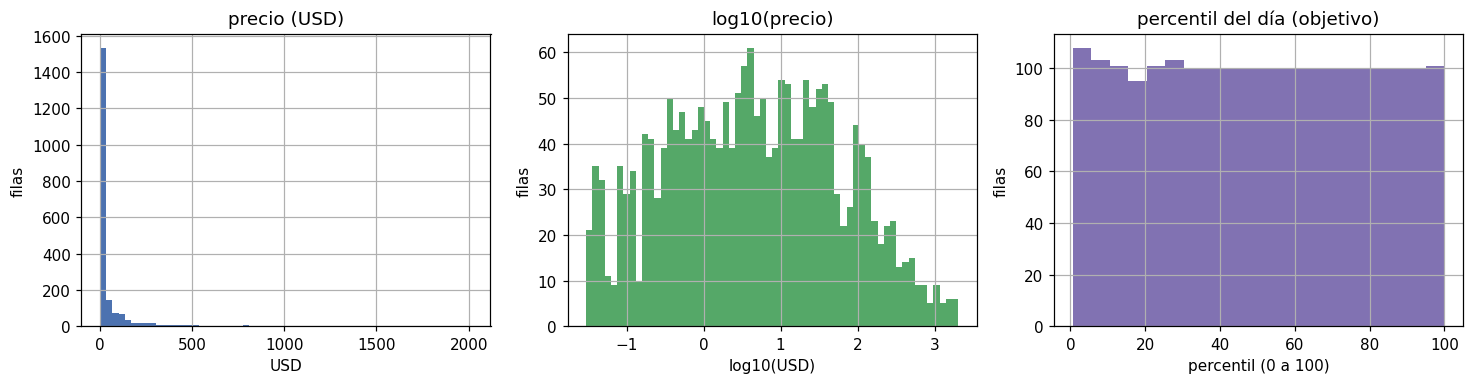

filas por decil del percentil (tiene que ser ~10 % cada uno):
percentil_precio
(-0.001, 10.0]    10.1
(10.0, 20.0]       9.8
(20.0, 30.0]      10.0
(30.0, 40.0]      10.0
(40.0, 50.0]      10.0
(50.0, 60.0]      10.0
(60.0, 70.0]       9.9
(70.0, 80.0]      10.0
(80.0, 90.0]      10.0
(90.0, 100.0]     10.0


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
p.hist(bins=60, ax=ax[0], color="#4C72B0")
ax[0].set_title("precio (USD)"); ax[0].set_xlabel("USD"); ax[0].set_ylabel("filas")
df["log_precio"].hist(bins=60, ax=ax[1], color="#55A868")
ax[1].set_title("log10(precio)"); ax[1].set_xlabel("log10(USD)"); ax[1].set_ylabel("filas")
df["percentil_precio"].hist(bins=20, ax=ax[2], color="#8172B2")
ax[2].set_title("percentil del día (objetivo)"); ax[2].set_xlabel("percentil (0 a 100)")
ax[2].set_ylabel("filas")
plt.tight_layout(); plt.show()

deciles = pd.cut(df["percentil_precio"], range(0, 101, 10), include_lowest=True)
print("filas por decil del percentil (tiene que ser ~10 % cada uno):")
print(deciles.value_counts(normalize=True).sort_index().mul(100).round(1).to_string())

**La pregunta de la consigna sobre la distribución del objetivo tiene una
respuesta corta:** el percentil está repartido parejo por construcción. No hay
una zona que se coma todo. La cola larga existe en el precio, y justamente por
eso trabajamos con su posición.

### 3.3 · De percentil a dólares (decisión 3)

El modelo predice un percentil, pero a cualquiera le interesa el precio. La
vuelta se hace con la distribución de precios del día: "percentil 90" se
traduce como "el precio por debajo del cual está el 90 % del mercado hoy".

Para ver cuánto pesa equivocarse se usa el **error real**: el MAE de la mejor
línea de base de la sección 9 (17 puntos). Es el piso que cualquier modelo de la
Entrega 3 tiene que mejorar, así que muestra el peor caso razonable.

In [13]:
# ✍ Error de referencia: el MAE de la mejor línea de base (sección 9, mediana
# por rareza y exterior). La sección 9 lo recalcula y avisa si dejó de coincidir.
ERROR_PUNTOS = 17


def percentil_a_dolares(percentil, precios_del_dia):
    # Traduce un percentil (0-100) al precio de ese día.
    return np.quantile(precios_del_dia, np.clip(percentil, 0, 100) / 100)


COL_MENOS = f"USD si se erra -{ERROR_PUNTOS}"
COL_MAS = f"USD si se erra +{ERROR_PUNTOS}"
traduccion = pd.DataFrame({"percentil": [5, 10, 25, 50, 75, 90, 95, 99]})
traduccion["USD"] = [round(float(percentil_a_dolares(q, p)), 2) for q in traduccion["percentil"]]
traduccion[COL_MENOS] = [round(float(percentil_a_dolares(q - ERROR_PUNTOS, p)), 2)
                         for q in traduccion["percentil"]]
traduccion[COL_MAS] = [round(float(percentil_a_dolares(q + ERROR_PUNTOS, p)), 2)
                       for q in traduccion["percentil"]]
traduccion["ancho del rango USD"] = (traduccion[COL_MAS] - traduccion[COL_MENOS]).round(2)
traduccion

,percentil,USD,USD si se erra -17,USD si se erra +17,ancho del rango USD
0,5,0.07,0.03,0.47,0.44
1,10,0.12,0.03,0.69,0.66
2,25,0.58,0.10,2.45,2.35
3,50,4.28,1.11,16.65,15.54
4,75,30.96,8.57,172.06,163.49
5,90,131.82,27.08,2017.62,1990.54
6,95,289.05,38.01,2017.62,1979.61
7,99,1110.64,54.78,2017.62,1962.84


**El límite, a la vista.** Con un error de ±17 puntos, en la zona barata el rango
posible es de centavos o pocos dólares; en la zona cara, de cientos. El error en
percentil es parecido en todas las zonas, pero **traducido a dólares crece en la
zona cara**. Hay que decirlo así, no esconderlo. Si el modelo de la Entrega 3 baja
el MAE, esta tabla se achica con él.

## 4 · Estabilidad del percentil entre fechas

Es la evidencia de la decisión 1. Sólo se calcula si hay más de un snapshot en
la carpeta; con uno solo, la celda lo avisa y sigue.

desde                                  2026-09-24
hasta                                  2026-10-15
skins en común                         938
cambio del nivel del mercado           -9.9%
Spearman entre fechas                  0.997
cambio medio del percentil (puntos)    2.68
cambio p95 del percentil (puntos)      6.87


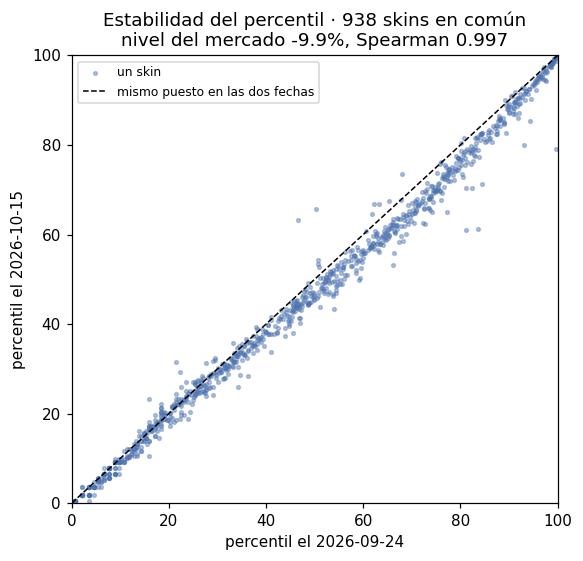

In [14]:
if len(fechas_disponibles) < 2:
    estabilidad = None
    print("Hay un solo snapshot: no se puede medir la estabilidad entre fechas.")
    print("Para mostrarla, correr el pipeline en otra fecha y volver a ejecutar.")
else:
    f0, f1 = str(fechas_disponibles[0]), str(fechas_disponibles[-1])
    a = df_todo[df_todo["fecha_snapshot"].dt.date.astype(str) == f0]
    b = df_todo[df_todo["fecha_snapshot"].dt.date.astype(str) == f1]
    m = a.merge(b, on="market_hash_name", suffixes=("_0", "_1"))
    nivel = m["sell_price_usd_1"].median() / m["sell_price_usd_0"].median() - 1
    spearman = m["sell_price_usd_0"].corr(m["sell_price_usd_1"], method="spearman")
    delta = (m["percentil_precio_1"] - m["percentil_precio_0"]).abs()
    estabilidad = {"desde": f0, "hasta": f1, "skins en común": len(m),
                   "cambio del nivel del mercado": f"{nivel:+.1%}",
                   "Spearman entre fechas": round(spearman, 3),
                   "cambio medio del percentil (puntos)": round(delta.mean(), 2),
                   "cambio p95 del percentil (puntos)": round(delta.quantile(.95), 2)}
    for k, v in estabilidad.items():
        print(f"{k:38s} {v}")

    fig, ax = plt.subplots(figsize=(5.4, 5.2))
    ax.scatter(m["percentil_precio_0"], m["percentil_precio_1"], s=6, alpha=0.4,
               color="#4C72B0", label="un skin")
    ax.plot([0, 100], [0, 100], color="k", lw=1, ls="--", label="mismo puesto en las dos fechas")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_xlabel(f"percentil el {f0}"); ax.set_ylabel(f"percentil el {f1}")
    ax.set_title(f"Estabilidad del percentil · {len(m)} skins en común\n"
                 f"nivel del mercado {nivel:+.1%}, Spearman {spearman:.3f}")
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

**Cómo se lee.** Si el nivel del mercado cambió varios puntos porcentuales
pero el Spearman entre fechas está cerca de 1, los precios se movieron **todos
juntos**: el orden se conservó. Eso es lo que hace del percentil un objetivo
estable y del precio en dólares uno que se sesga.

En el gráfico cada punto es un skin: cuanto más pegados a la diagonal, más
conservaron su puesto entre una fecha y la otra.

## 5 · Medidas, semáforo y fichas

Las plantillas y los cortes de la cátedra, sobre el valor absoluto:

| Plantilla | Medida | Rojo / Amarillo / Verde |
|---|---|---|
| comparación (2 grupos) | separación (d) | < 0,2 · 0,2-0,8 · > 0,8 |
| comparación (n grupos) | η² | < 0,05 · 0,05-0,25 · > 0,25 |
| asociación | correlación (+ brecha) | < 0,2 · 0,2-0,6 · > 0,6 |

### La lección de la versión anterior

Las cuatro hipótesis anteriores dieron amarillo por la misma razón: comparaban
**skins distintos entre sí**, y lo que más mueve el precio —qué skin es, su
diseño, su popularidad— no está en ninguna columna. Ese ruido tapaba todo.

La solución es **comparar cada skin consigo mismo**: el mismo skin en dos
exteriores, o en versión souvenir y normal. Al dejar fijo el skin, el ruido del
diseño desaparece. Se llama **comparación pareada**, y es la plantilla de
"comparación de dos grupos" aplicada a pares.

In [15]:
CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    if valor is None or (isinstance(valor, float) and math.isnan(valor)):
        return "sin dato"
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


def eta2(numerica, grupos):
    """Qué proporción de la varianza de la numérica explica el grupo."""
    d = pd.DataFrame({"y": numerica, "g": grupos}).dropna()
    if d["g"].nunique() < 2 or len(d) < 3:
        return float("nan")
    total = ((d["y"] - d["y"].mean()) ** 2).sum()
    entre = d.groupby("g")["y"].apply(
        lambda s: len(s) * (s.mean() - d["y"].mean()) ** 2).sum()
    return entre / total if total else float("nan")


def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambas."""
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(d) < 3 or d["x"].nunique() < 2:
        return {"pearson": float("nan"), "spearman": float("nan"),
                "brecha": float("nan"), "n": len(d)}
    p, s = d["x"].corr(d["y"]), d["x"].corr(d["y"], method="spearman")
    return {"pearson": round(p, 3), "spearman": round(s, 3),
            "brecha": round(abs(s) - abs(p), 3), "n": len(d)}


def separacion_pareada(diferencias):
    """d de los pares: la diferencia media en unidades de su desvío."""
    d = pd.Series(diferencias).dropna()
    if len(d) < 3 or d.std() == 0:
        return float("nan")
    return d.mean() / d.std()

In [16]:
FICHAS = []


def registrar_ficha(nombre, pregunta, afirmacion, esperaba, plantilla, medida,
                    valor, movimientos, decision, grafico=""):
    zona = semaforo(valor, medida)
    ficha = {"hipótesis": nombre, "pregunta": pregunta, "afirmación": afirmacion,
             "qué esperaba ver": esperaba, "plantilla": plantilla,
             "medida": f"{medida} = {valor:.3f}" if valor == valor else f"{medida} = sin dato",
             "valor": round(valor, 3) if valor == valor else None, "zona": zona,
             "movimientos": movimientos, "decisión": decision, "gráfico": grafico}
    FICHAS[:] = [f for f in FICHAS if f["hipótesis"] != nombre] + [ficha]
    print("=" * 78)
    print(f"FICHA · {nombre}   [{pregunta}]")
    print("=" * 78)
    for campo in ("afirmación", "qué esperaba ver", "plantilla", "medida",
                  "zona", "movimientos", "decisión"):
        print(f"{campo:18s}  " +
              textwrap.fill(str(ficha[campo]), 58, subsequent_indent=" " * 20))
    print()
    return ficha

## 6 · Las cuatro hipótesis

Dos de dominio y dos sobre columnas del modelo. Todas se miden contra
`percentil_precio`. La afirmación y lo que esperamos ver están escritos
**antes** de correr cada medida.

### H1 · El arma explica el precio más allá de la rareza
**dominio · comparación de n grupos (η²)**

**Afirmación.** A igual rareza, el arma cambia la posición en el mercado: la
demanda se concentra en pocas armas (AK-47, AWP, M4), así que sus skins valen
más que los de armas poco usadas.

**Qué esperamos ver.** η² del arma alto en general y, lo que importa, **que se
sostenga dentro de cada rareza**. Si dentro de una rareza cayera a casi cero, el
arma no aportaría nada propio.

**Contra qué se compara.** Partir las filas en *k* grupos siempre "explica" algo,
aunque el grupo no tenga nada que ver con el precio: en promedio, η² da
(*k* − 1) / (*n* − 1), con *k* armas y *n* filas. Por eso cada rareza se mira
contra ese número, y no sólo contra los cortes del semáforo.

In [17]:
e_arma = eta2(df["percentil_precio"], df["weapon"])
e_rareza = eta2(df["percentil_precio"], df["rarity"])
print(f"η² del arma, en general  : {e_arma:.3f}  {semaforo(e_arma, 'eta2')}")
print(f"η² de la rareza (contexto): {e_rareza:.3f}  {semaforo(e_rareza, 'eta2')}")

orden_rareza = df.groupby("rarity")["rarity_orden"].first()
dentro = []
for r in df["rarity"].dropna().unique():
    s = df[df["rarity"] == r]
    k, n = s["weapon"].nunique(), len(s)
    if n >= 40 and k >= 3:
        e = eta2(s["percentil_precio"], s["weapon"])
        azar = (k - 1) / (n - 1)
        dentro.append({"rareza": r, "filas": n, "armas": k, "η² arma": round(e, 3),
                       "η² del azar": round(azar, 3), "veces el azar": round(e / azar, 1),
                       "zona": semaforo(e, "eta2"), "_orden": orden_rareza.get(r, 99)})
tabla_h1 = (pd.DataFrame(dentro).sort_values("_orden").drop(columns="_orden")
            .reset_index(drop=True))
print("\nη² del arma DENTRO de cada rareza, contra lo que da el azar:")
print(tabla_h1.to_string(index=False))
e_arma_dentro = tabla_h1["η² arma"].median() if len(tabla_h1) else float("nan")
cerca_del_azar = tabla_h1.loc[tabla_h1["veces el azar"] < 1.5, "rareza"].tolist()
print(f"\nmediana dentro de las rarezas: {e_arma_dentro:.3f}",
      semaforo(e_arma_dentro, "eta2"))
print("rarezas donde el arma queda pegada al azar (menos de 1,5 veces):",
      cerca_del_azar or "ninguna")

η² del arma, en general  : 0.217  amarillo
η² de la rareza (contexto): 0.408  verde

η² del arma DENTRO de cada rareza, contra lo que da el azar:
          rareza  filas  armas  η² arma  η² del azar  veces el azar     zona
  Consumer Grade    263     24    0.224        0.088            2.5 amarillo
Industrial Grade    234     31    0.415        0.129            3.2    verde
  Mil-Spec Grade    683     34    0.214        0.048            4.4 amarillo
      Restricted    383     30    0.375        0.076            4.9    verde
      Classified    260     31    0.408        0.116            3.5    verde
          Covert    189     18    0.185        0.090            2.0 amarillo

mediana dentro de las rarezas: 0.299 verde
rarezas donde el arma queda pegada al azar (menos de 1,5 veces): ninguna


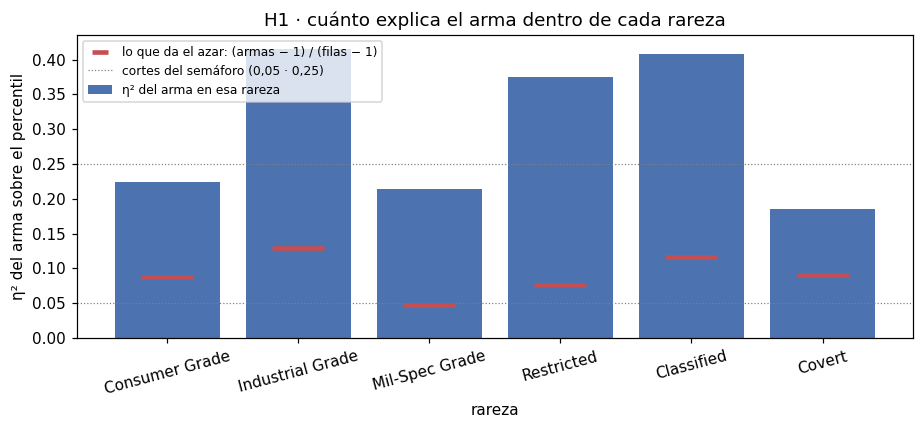

las 5 armas más caras  : ['AK-47', 'AWP', 'M4A4', 'M4A1-S', 'Desert Eagle']
las 5 armas más baratas: ['SG 553', 'MP5-SD', 'UMP-45', 'Tec-9', 'XM1014']


In [18]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(tabla_h1))
ax.bar(x, tabla_h1["η² arma"], color="#4C72B0", label="η² del arma en esa rareza")
ax.scatter(x, tabla_h1["η² del azar"], color="#C44E52", marker="_", s=1200,
           linewidths=3, zorder=3, label="lo que da el azar: (armas − 1) / (filas − 1)")
for i, corte in enumerate(CORTES["eta2"]):
    ax.axhline(corte, color="gray", lw=0.8, ls=":",
               label="cortes del semáforo (0,05 · 0,25)" if i == 0 else None)
ax.set_xticks(x); ax.set_xticklabels(tabla_h1["rareza"], rotation=15)
ax.set_xlabel("rareza"); ax.set_ylabel("η² del arma sobre el percentil")
ax.set_title("H1 · cuánto explica el arma dentro de cada rareza")
ax.legend(loc="upper left", fontsize=8, markerscale=0.3)
plt.tight_layout(); plt.show()

orden_armas = df.groupby("weapon")["percentil_precio"].median().sort_values()
print("las 5 armas más caras  :", list(orden_armas.tail(5).index[::-1]))
print("las 5 armas más baratas:", list(orden_armas.head(5).index))

In [19]:
_z = semaforo(e_arma_dentro, "eta2")
_dec = {
    "verde": "Confirmada. El arma aporta por encima de la rareza: weapon entra al modelo (one-hot).",
    "amarillo": "Confirmada con reserva. El arma aporta, pero moderado dentro de cada rareza: entra al modelo.",
    "rojo": "Refutada. Dentro de una rareza el arma casi no cambia la posición: su efecto global venía de la rareza.",
    "sin dato": "Sin datos suficientes.",
}[_z]
if cerca_del_azar and _z != "sin dato":
    _dec += f" En {', '.join(cerca_del_azar)} el efecto no se distingue del azar."
registrar_ficha(
    "H1 · el arma explica el precio más allá de la rareza", "responder (dominio)",
    "A igual rareza, el arma cambia la posición del skin en el mercado.",
    "η² alto en general y que se sostenga dentro de cada rareza, por encima del azar.",
    "comparación de n grupos", "eta2", e_arma_dentro,
    f"medido dentro de cada rareza y contra el azar (η² global {e_arma:.3f}, rareza {e_rareza:.3f})",
    _dec, "η² del arma por rareza, contra lo que da el azar")

FICHA · H1 · el arma explica el precio más allá de la rareza   [responder (dominio)]
afirmación          A igual rareza, el arma cambia la posición del skin en el
                    mercado.
qué esperaba ver    η² alto en general y que se sostenga dentro de cada
                    rareza, por encima del azar.
plantilla           comparación de n grupos
medida              eta2 = 0.299
zona                verde
movimientos         medido dentro de cada rareza y contra el azar (η² global
                    0.217, rareza 0.408)
decisión            Confirmada. El arma aporta por encima de la rareza: weapon
                    entra al modelo (one-hot).



{'hipótesis': 'H1 · el arma explica el precio más allá de la rareza',
 'pregunta': 'responder (dominio)',
 'afirmación': 'A igual rareza, el arma cambia la posición del skin en el mercado.',
 'qué esperaba ver': 'η² alto en general y que se sostenga dentro de cada rareza, por encima del azar.',
 'plantilla': 'comparación de n grupos',
 'medida': 'eta2 = 0.299',
 'valor': 0.299,
 'zona': 'verde',
 'movimientos': 'medido dentro de cada rareza y contra el azar (η² global 0.217, rareza 0.408)',
 'decisión': 'Confirmada. El arma aporta por encima de la rareza: weapon entra al modelo (one-hot).',
 'gráfico': 'η² del arma por rareza, contra lo que da el azar'}

### H2 · Ser souvenir tiene prima de precio
**dominio · comparación pareada**

**Afirmación.** La versión souvenir de un skin está más arriba en el mercado
que su versión normal, porque sólo sale de paquetes de torneo y hay menos.

**Qué esperamos ver.** Que, comparando **el mismo skin en el mismo exterior**,
la versión souvenir tenga un percentil claramente mayor.

**Por qué pareada.** Así el diseño del skin queda fijo y lo único que cambia
es ser souvenir. Comparar souvenirs contra no-souvenirs en general mezclaría
skins distintos, que es el error de la versión anterior.

**Si no hay pares suficientes.** Las versiones souvenir empiezan con la palabra
"Souvenir" y Steam ordena por nombre, así que en una muestra quedan lejos de su
versión normal. Si hay menos de 20 pares, la celda corre la **hipótesis de
reserva**: ¿el mercado paga exactamente la escasez?

**Cómo sale la medida.** Para cada par se calcula la diferencia de percentil
(souvenir − normal). La separación es la **media de esas diferencias dividida por
su desvío**: cuántos desvíos se aleja de cero la diferencia típica. Es la
plantilla de dos grupos, pero calculada sobre las diferencias de cada par y no
entre dos grupos independientes.

In [20]:
sin_st = df[~df["stattrak"].fillna(False).astype(bool)]
souv = sin_st[sin_st["souvenir"].fillna(False).astype(bool)]
norm = sin_st[~sin_st["souvenir"].fillna(False).astype(bool)]
pares = souv.merge(norm, on=["skin_id", "wear"], suffixes=("_s", "_n"))
pares["dif_percentil"] = pares["percentil_precio_s"] - pares["percentil_precio_n"]
pares["razon_precio"] = pares["sell_price_usd_s"] / pares["sell_price_usd_n"]
N_PARES = len(pares)
print("pares souvenir / normal del mismo skin y exterior:", N_PARES)
USAR_RESERVA = N_PARES < 20

pares souvenir / normal del mismo skin y exterior: 55


diferencia media de percentil   : +27.8 puntos (desvío 28.6)
diferencia mediana de percentil : +23.1 puntos
la souvenir vale, en la mediana : 12.93 veces más
pares donde la souvenir es más cara: 84%
separación pareada = media / desvío de las diferencias = 0.971 | zona: verde


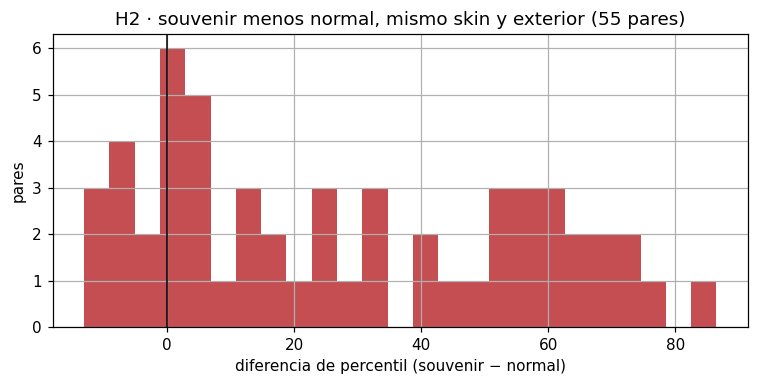

FICHA · H2 · ser souvenir tiene prima de precio   [responder (dominio)]
afirmación          La versión souvenir de un skin está más arriba en el
                    mercado que la normal.
qué esperaba ver    Percentil claramente mayor comparando el mismo skin en el
                    mismo exterior.
plantilla           comparación de dos grupos, en pares (d sobre las
                    diferencias de cada par)
medida              separacion = 0.971
zona                verde
movimientos         ninguno: el diseño ya queda fijo al parear (55 pares;
                    diferencia media +27.8, desvío 28.6)
decisión            Confirmada. Ser souvenir sube la posición del mismo skin:
                    souvenir entra al modelo.



In [21]:
if not USAR_RESERVA:
    dif = pares["dif_percentil"]
    d2 = separacion_pareada(dif)
    print(f"diferencia media de percentil   : {dif.mean():+.1f} puntos (desvío {dif.std():.1f})")
    print(f"diferencia mediana de percentil : {dif.median():+.1f} puntos")
    print(f"la souvenir vale, en la mediana : {pares['razon_precio'].median():.2f} veces más")
    print(f"pares donde la souvenir es más cara: {(dif > 0).mean():.0%}")
    print(f"separación pareada = media / desvío de las diferencias = {d2:.3f} | zona:",
          semaforo(d2, "separacion"))

    fig, ax = plt.subplots(figsize=(7, 3.6))
    dif.hist(bins=25, ax=ax, color="#C44E52")
    ax.axvline(0, color="k", lw=1)
    ax.set_title(f"H2 · souvenir menos normal, mismo skin y exterior ({N_PARES} pares)")
    ax.set_xlabel("diferencia de percentil (souvenir − normal)")
    ax.set_ylabel("pares")
    plt.tight_layout(); plt.show()

    _z = semaforo(d2, "separacion")
    _dec = {"verde": "Confirmada. Ser souvenir sube la posición del mismo skin: souvenir entra al modelo.",
            "amarillo": "Confirmada con reserva. Hay prima, pero varía mucho entre skins: entra al modelo.",
            "rojo": "Refutada. Comparando el mismo skin, ser souvenir no cambia la posición.",
            "sin dato": "Sin datos suficientes."}[_z]
    registrar_ficha(
        "H2 · ser souvenir tiene prima de precio", "responder (dominio)",
        "La versión souvenir de un skin está más arriba en el mercado que la normal.",
        "Percentil claramente mayor comparando el mismo skin en el mismo exterior.",
        "comparación de dos grupos, en pares (d sobre las diferencias de cada par)",
        "separacion", d2,
        f"ninguno: el diseño ya queda fijo al parear ({N_PARES} pares; diferencia media "
        f"{dif.mean():+.1f}, desvío {dif.std():.1f})",
        _dec, "histograma de las diferencias por par")
else:
    print(f"Sólo {N_PARES} pares: se corre la hipótesis de reserva (celda siguiente).")

In [22]:
# Hipótesis de reserva: ¿el mercado paga exactamente la escasez?
# Cada peldaño de rareza es 5 veces más raro que el anterior. Si el precio fuera
# pura escasez, cada peldaño también lo multiplicaría por 5.
if USAR_RESERVA:
    base = df[(df["origen"] == "caja")
              & ~df["stattrak"].fillna(False).astype(bool)
              & ~df["souvenir"].fillna(False).astype(bool)].dropna(subset=["rarity_orden"])
    a2 = asociacion(base["rarity_orden"], base["log_precio"])
    pendiente = np.polyfit(base["rarity_orden"], base["log_precio"], 1)[0]
    multiplicador = 10 ** pendiente
    print("filas de caja, sin StatTrak ni Souvenir:", len(base))
    print("asociación rareza - log(precio):", a2, "| zona:", semaforo(a2["pearson"], "correlacion"))
    print(f"cada peldaño multiplica el precio por: {multiplicador:.2f}  (la escasez es x5)")

    if 3.5 <= multiplicador <= 7:
        lectura = f"el mercado paga aproximadamente la escasez (x{multiplicador:.1f} contra x5)"
    elif multiplicador > 7:
        lectura = f"el mercado paga más que la escasez (x{multiplicador:.1f}): hay prima de prestigio"
    else:
        lectura = f"el mercado paga menos que la escasez (x{multiplicador:.1f}): pesa otra cosa, como el diseño"
    print("lectura:", lectura)

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.scatter(base["rarity_orden"], base["log_precio"], s=8, alpha=0.4, color="#4C72B0")
    xs = np.array([base["rarity_orden"].min(), base["rarity_orden"].max()])
    ax.plot(xs, np.polyval(np.polyfit(base["rarity_orden"], base["log_precio"], 1), xs),
            color="#C44E52", lw=2, label=f"pendiente: x{multiplicador:.1f} por peldaño")
    ax.set_xlabel("peldaño de rareza (rarity_orden)"); ax.set_ylabel("log10(precio USD)")
    ax.set_title("H2 (reserva) · rareza contra log del precio")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

    registrar_ficha(
        "H2 · el mercado paga exactamente la escasez", "responder (dominio)",
        "Cada peldaño de rareza es 5 veces más raro, así que debería multiplicar el precio por 5.",
        "Asociación fuerte entre rareza y log del precio, con un multiplicador cercano a 5.",
        "asociación (dos numéricas)", "correlacion", a2["pearson"],
        f"traducir la pendiente a multiplicador: {lectura}",
        f"La rareza explica el precio y {lectura}.", "rareza contra log del precio")

### H3 · El exterior mueve el precio del mismo skin
**columna del modelo · asociación dentro de cada skin**

**Afirmación.** Dentro de un mismo skin, cuanto más gastado el exterior, más
abajo queda en el mercado. `wear_orden` tiene que entrar al modelo.

**Qué esperamos ver.** Una correlación fuerte y negativa **dentro de cada
skin**, mucho más clara que la medida en general. En la versión anterior, el
exterior daba un η² de apenas 0,052 en general: esperamos que sea porque se
comparaban skins distintos, no porque el exterior no importe.

**Cómo se lee la medida.** Cada correlación se calcula con los 3 a 5 exteriores
de un skin, así que una sola es ruidosa. Por eso se reportan dos números: el
**promedio de las correlaciones** (la medida de la plantilla) y el **porcentaje de
skins donde más gastado es más barato**, que se entiende sin estadística.

In [23]:
e_wear_global = eta2(df["percentil_precio"], df["wear"])
print(f"η² del exterior, en general (como antes): {e_wear_global:.3f}",
      semaforo(e_wear_global, "eta2"))

solo_base = df[~df["stattrak"].fillna(False).astype(bool)
               & ~df["souvenir"].fillna(False).astype(bool)]
por_skin = []
for sid, g in solo_base.groupby("skin_id"):
    # al menos 3 exteriores, y que el percentil varíe (si no, no hay correlación)
    if g["wear_orden"].nunique() >= 3 and g["percentil_precio"].nunique() > 1:
        por_skin.append({"skin_id": sid, "puntos": len(g),
                         "corr": g["wear_orden"].corr(g["percentil_precio"], method="spearman")})
por_skin = pd.DataFrame(por_skin).dropna()
corr_por_skin = por_skin["corr"]
r3 = corr_por_skin.mean()
pct_negativa = (corr_por_skin < 0).mean()
print(f"\nskins con al menos 3 exteriores: {len(corr_por_skin)}")
print(f"puntos por correlación (exteriores de cada skin): "
      f"{por_skin['puntos'].min()} a {por_skin['puntos'].max()}")
print(f"correlación media DENTRO de cada skin: {r3:.3f}  {semaforo(r3, 'correlacion')}")
print(f"skins donde más gastado = más barato  : {pct_negativa:.0%}")

η² del exterior, en general (como antes): 0.051 amarillo

skins con al menos 3 exteriores: 209
puntos por correlación (exteriores de cada skin): 3 a 5
correlación media DENTRO de cada skin: -0.700  verde
skins donde más gastado = más barato  : 92%


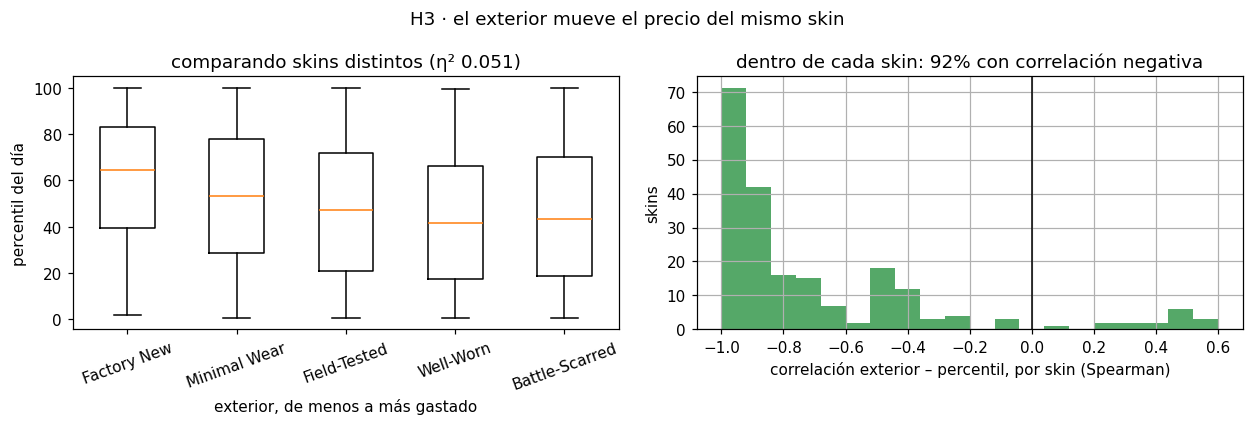

In [24]:
ORDEN_EXTERIORES = ["Factory New", "Minimal Wear", "Field-Tested", "Well-Worn",
                    "Battle-Scarred"]
orden_w = [w for w in ORDEN_EXTERIORES if w in df["wear"].unique()]

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].boxplot([df.loc[df["wear"] == w, "percentil_precio"] for w in orden_w])
ax[0].set_xticks(range(1, len(orden_w) + 1))
ax[0].set_xticklabels(orden_w, rotation=20)
ax[0].set_title(f"comparando skins distintos (η² {e_wear_global:.3f})")
ax[0].set_xlabel("exterior, de menos a más gastado"); ax[0].set_ylabel("percentil del día")

corr_por_skin.hist(bins=20, ax=ax[1], color="#55A868")
ax[1].axvline(0, color="k", lw=1)
ax[1].set_title(f"dentro de cada skin: {pct_negativa:.0%} con correlación negativa")
ax[1].set_xlabel("correlación exterior – percentil, por skin (Spearman)")
ax[1].set_ylabel("skins")
plt.suptitle("H3 · el exterior mueve el precio del mismo skin")
plt.tight_layout(); plt.show()

In [25]:
_z = semaforo(r3, "correlacion")
_dec = {"verde": "Confirmada. Dentro del mismo skin el exterior ordena el precio: wear_orden entra al modelo.",
        "amarillo": "Confirmada con reserva. El efecto existe pero varía entre skins: wear_orden entra.",
        "rojo": "Refutada. Ni siquiera dentro del mismo skin el exterior ordena el precio.",
        "sin dato": "Sin datos suficientes."}[_z]
registrar_ficha(
    "H3 · el exterior mueve el precio del mismo skin", "predecir (columna del modelo)",
    "Dentro de un mismo skin, más gastado quiere decir más abajo en el mercado.",
    "Correlación fuerte y negativa dentro de cada skin, mucho más clara que en general.",
    "asociación (dentro de cada skin: promedio de las correlaciones de Spearman)",
    "correlacion", r3,
    f"medido dentro de cada skin en vez de entre skins (η² general {e_wear_global:.3f}). "
    f"En el {pct_negativa:.0%} de los {len(corr_por_skin)} skins, más gastado es más barato; "
    f"cada correlación usa {por_skin['puntos'].min()} a {por_skin['puntos'].max()} exteriores",
    _dec, "boxplot por exterior (ordenado) contra correlaciones dentro de cada skin")

FICHA · H3 · el exterior mueve el precio del mismo skin   [predecir (columna del modelo)]
afirmación          Dentro de un mismo skin, más gastado quiere decir más
                    abajo en el mercado.
qué esperaba ver    Correlación fuerte y negativa dentro de cada skin, mucho
                    más clara que en general.
plantilla           asociación (dentro de cada skin: promedio de las
                    correlaciones de Spearman)
medida              correlacion = -0.700
zona                verde
movimientos         medido dentro de cada skin en vez de entre skins (η²
                    general 0.051). En el 92% de los 209
                    skins, más gastado es más barato; cada
                    correlación usa 3 a 5 exteriores
decisión            Confirmada. Dentro del mismo skin el exterior ordena el
                    precio: wear_orden entra al modelo.



{'hipótesis': 'H3 · el exterior mueve el precio del mismo skin',
 'pregunta': 'predecir (columna del modelo)',
 'afirmación': 'Dentro de un mismo skin, más gastado quiere decir más abajo en el mercado.',
 'qué esperaba ver': 'Correlación fuerte y negativa dentro de cada skin, mucho más clara que en general.',
 'plantilla': 'asociación (dentro de cada skin: promedio de las correlaciones de Spearman)',
 'medida': 'correlacion = -0.700',
 'valor': np.float64(-0.7),
 'zona': 'verde',
 'movimientos': 'medido dentro de cada skin en vez de entre skins (η² general 0.051). En el 92% de los 209 skins, más gastado es más barato; cada correlación usa 3 a 5 exteriores',
 'decisión': 'Confirmada. Dentro del mismo skin el exterior ordena el precio: wear_orden entra al modelo.',
 'gráfico': 'boxplot por exterior (ordenado) contra correlaciones dentro de cada skin'}

### H4 · La probabilidad de drop aporta más allá de la rareza
**columna del modelo · asociación controlada · candidata a refutada**

**Afirmación.** `neg_log_p_item` —qué tan improbable es sacar ese item exacto
de su caja— explica la posición en el mercado por encima de lo que ya dice la
rareza.

**Qué esperamos ver.** Honestamente, que no. `p_item` se calcula con la rareza,
el exterior, el StatTrak y el tamaño de la colección: es casi todo información
que ya está en otras columnas. La versión anterior ya mostró que dentro de una
rareza la relación caía a entre 0,1 y 0,24. Si se confirma, es la hipótesis
refutada que pide la consigna, con un número que la sostiene.

In [26]:
caja = df[df["neg_log_p_item"].notna()]
a4 = asociacion(caja["neg_log_p_item"], caja["percentil_precio"])
print("en general:", a4, "|", semaforo(a4["pearson"], "correlacion"))

dentro4 = []
for r in caja["rarity"].dropna().unique():
    s = caja[caja["rarity"] == r]
    if len(s) >= 30:
        a = asociacion(s["neg_log_p_item"], s["percentil_precio"])
        dentro4.append({"rareza": r, "filas": len(s), "pearson": a["pearson"],
                        "zona": semaforo(a["pearson"], "correlacion")})
tabla_h4 = pd.DataFrame(dentro4).sort_values("filas", ascending=False)
print("\ndentro de cada rareza:")
print(tabla_h4.to_string(index=False))
r4 = tabla_h4["pearson"].abs().median() if len(tabla_h4) else float("nan")
print(f"\nmediana dentro de las rarezas: {r4:.3f}", semaforo(r4, "correlacion"))

en general: {'pearson': np.float64(0.624), 'spearman': np.float64(0.606), 'brecha': np.float64(-0.018), 'n': 973} | verde

dentro de cada rareza:
        rareza  filas  pearson     zona
Mil-Spec Grade    405   -0.027     rojo
    Restricted    249    0.236 amarillo
    Classified    184    0.215 amarillo
        Covert    135    0.444 amarillo

mediana dentro de las rarezas: 0.225 amarillo


**Qué mirar.** Si la probabilidad de drop aportara algo propio, **dentro de cada
color** la nube subiría (la recta de ese color tendría pendiente). Si la nube
entera sube sólo porque se pasa de un color al otro, lo que se está midiendo es
la rareza.

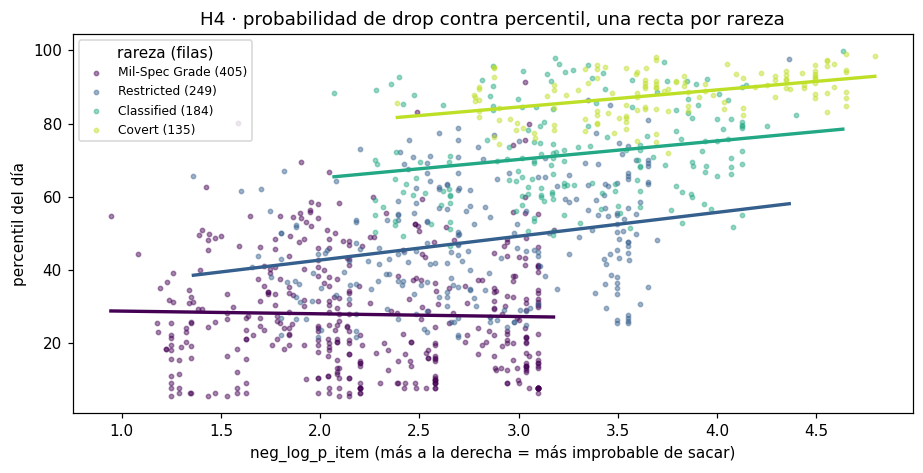

In [27]:
orden_r4 = caja.groupby("rarity")["rarity_orden"].first().sort_values().index
colores = plt.cm.viridis(np.linspace(0, 0.9, len(orden_r4)))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for color, r in zip(colores, orden_r4):
    s = caja[caja["rarity"] == r]
    ax.scatter(s["neg_log_p_item"], s["percentil_precio"], s=8, alpha=0.45,
               color=color, label=f"{r} ({len(s)})")
    if len(s) >= 30 and s["neg_log_p_item"].nunique() > 1:
        pend, inter = np.polyfit(s["neg_log_p_item"], s["percentil_precio"], 1)
        xs = np.array([s["neg_log_p_item"].min(), s["neg_log_p_item"].max()])
        ax.plot(xs, inter + pend * xs, color=color, lw=2.2)
ax.set_xlabel("neg_log_p_item (más a la derecha = más improbable de sacar)")
ax.set_ylabel("percentil del día")
ax.set_title("H4 · probabilidad de drop contra percentil, una recta por rareza")
ax.legend(title="rareza (filas)", fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

In [28]:
_z = semaforo(r4, "correlacion")
_dec = {"verde": "Confirmada. La probabilidad de drop aporta por encima de la rareza: neg_log_p_item entra.",
        "amarillo": "Inconclusa. Aporta algo por encima de la rareza, pero poco: entra como variable secundaria.",
        "rojo": "Refutada. Dentro de una rareza casi no aporta: lo que parecía su efecto era la rareza. Queda como secundaria.",
        "sin dato": "Sin datos suficientes."}[_z]
registrar_ficha(
    "H4 · la probabilidad de drop aporta más allá de la rareza", "predecir (columna del modelo)",
    "neg_log_p_item explica la posición en el mercado por encima de la rareza.",
    "Que no: dentro de una rareza la relación debería caer mucho.",
    "asociación (controlando la rareza)", "correlacion", r4,
    f"medido dentro de cada rareza (en general: {a4['pearson']})",
    _dec, "dispersión coloreada por rareza, con una recta por color")

FICHA · H4 · la probabilidad de drop aporta más allá de la rareza   [predecir (columna del modelo)]
afirmación          neg_log_p_item explica la posición en el mercado por
                    encima de la rareza.
qué esperaba ver    Que no: dentro de una rareza la relación debería caer
                    mucho.
plantilla           asociación (controlando la rareza)
medida              correlacion = 0.225
zona                amarillo
movimientos         medido dentro de cada rareza (en general: 0.624)
decisión            Inconclusa. Aporta algo por encima de la rareza, pero
                    poco: entra como variable secundaria.



{'hipótesis': 'H4 · la probabilidad de drop aporta más allá de la rareza',
 'pregunta': 'predecir (columna del modelo)',
 'afirmación': 'neg_log_p_item explica la posición en el mercado por encima de la rareza.',
 'qué esperaba ver': 'Que no: dentro de una rareza la relación debería caer mucho.',
 'plantilla': 'asociación (controlando la rareza)',
 'medida': 'correlacion = 0.225',
 'valor': 0.225,
 'zona': 'amarillo',
 'movimientos': 'medido dentro de cada rareza (en general: 0.624)',
 'decisión': 'Inconclusa. Aporta algo por encima de la rareza, pero poco: entra como variable secundaria.',
 'gráfico': 'dispersión coloreada por rareza, con una recta por color'}

## 7 · La tabla de columnas candidatas

Las cinco columnas que pide la consigna: **Columna · Qué mide · Zona · Decisión ·
¿Existiría al predecir?**

- **Zona** es el color de la medida que respalda la decisión: la de la ficha cuando
  la columna tiene una, o una medida de respaldo calculada acá cuando no.
- Donde la decisión es de dominio (no de un número), no hay color, y se dice por qué.
- La última columna es el chequeo de fuga: ¿existiría esa columna en el momento de
  predecir el percentil de un skin recién lanzado?

In [29]:
# La fuga, con número: sell_listings contra el percentil
a_fuga = asociacion(np.log10(df["sell_listings"].clip(lower=1)), df["percentil_precio"])
print("log(sell_listings) contra el percentil:", a_fuga)
print("Correlaciona fuerte, y por eso es sospechosa: se cuenta en el mismo momento")
print("que el precio y cambia en respuesta a él. Para un skin nuevo, no existe.")

log(sell_listings) contra el percentil: {'pearson': np.float64(-0.77), 'spearman': np.float64(-0.772), 'brecha': np.float64(0.002), 'n': 2012}
Correlaciona fuerte, y por eso es sospechosa: se cuenta en el mismo momento
que el precio y cambia en respuesta a él. Para un skin nuevo, no existe.


In [30]:
# Medidas de respaldo para las columnas que entran y no tienen ficha propia
sin_souv = df[~df["souvenir"].fillna(False).astype(bool)]
_es_st = sin_souv["stattrak"].fillna(False).astype(bool)
pares_st = sin_souv[_es_st].merge(sin_souv[~_es_st], on=["skin_id", "wear"],
                                   suffixes=("_st", "_n"))
d_stattrak = separacion_pareada(pares_st["percentil_precio_st"] - pares_st["percentil_precio_n"])
e_origen = eta2(df["percentil_precio"], df["origen"])

print(f"StatTrak, pareado (mismo skin y exterior): d = {d_stattrak:.3f} con {len(pares_st)} pares"
      f" | {semaforo(d_stattrak, 'separacion')}")
print(f"origen: η² = {e_origen:.3f} | {semaforo(e_origen, 'eta2')}")
print(f"rareza: η² = {e_rareza:.3f} | {semaforo(e_rareza, 'eta2')}")

ZONA_DE_FICHA = {f["hipótesis"].split(" ·")[0]: f"{f['zona']} · {f['hipótesis'].split(' ·')[0]} ({f['medida']})"
                 for f in FICHAS}


def zona_de(valor, medida, etiqueta):
    if valor is None or valor != valor:
        return f"sin dato ({etiqueta})"
    return f"{semaforo(valor, medida)} ({etiqueta} = {valor:.3f})"


ZONA = {
    "rarity_orden": zona_de(e_rareza, "eta2", "η² rareza"),
    "weapon": ZONA_DE_FICHA.get("H1", "sin ficha"),
    "wear_orden": ZONA_DE_FICHA.get("H3", "sin ficha"),
    "stattrak": zona_de(d_stattrak, "separacion", f"d pareada, {len(pares_st)} pares"),
    "souvenir": ZONA_DE_FICHA.get("H2", "sin ficha"),
    "origen": zona_de(e_origen, "eta2", "η² origen"),
    "neg_log_p_item": ZONA_DE_FICHA.get("H4", "sin ficha"),
    "sell_listings": zona_de(a_fuga["pearson"], "correlacion", "r con el percentil")
                     + ": por eso es sospechosa",
}

StatTrak, pareado (mismo skin y exterior): d = 0.838 con 79 pares | verde
origen: η² = 0.123 | amarillo
rareza: η² = 0.408 | verde


In [31]:
DOMINIO = "— (decisión de dominio)"
SUPUESTO_P_WEAR = ("parcialmente validado: el orden se sostiene (correlación 0,70), "
                   "pero falla en los extremos; p_wear no entra al modelo")
candidatas = pd.DataFrame([
 ("rarity_orden", "Peldaño de rareza (0 = Consumer … 5 = Covert); cada uno es 5 veces más raro",
  ZONA["rarity_orden"], "Entra", "Sí: Valve la publica al lanzar"),
 ("weapon", "Qué arma es (AK-47, AWP, ...)", ZONA["weapon"], "Entra (one-hot) - H1", "Sí"),
 ("wear_orden", "Exterior, de Factory New (0) a Battle-Scarred (4)", ZONA["wear_orden"],
  "Entra - H3", "Sí"),
 ("stattrak", "Si la versión cuenta las bajas", ZONA["stattrak"], "Entra", "Sí"),
 ("souvenir", "Si es la versión de un paquete de torneo", ZONA["souvenir"], "Entra - H2", "Sí"),
 ("origen", "Cómo se obtiene: caja, paquete souvenir, drop de mapa", ZONA["origen"],
  "Entra (one-hot)", "Sí"),
 ("neg_log_p_item", "Qué tan improbable es sacar ese item exacto de su caja (−log10)",
  ZONA["neg_log_p_item"], "Secundaria - H4, con imputación", "Sí"),
 ("antiguedad_col_dias", "Días desde el lanzamiento de la colección", DOMINIO,
  "Sale: para un skin nuevo vale ~0, fuera del rango de entrenamiento", "Sí, pero ~0"),
 ("caja_discontinuada", "Si la caja salió del pool de drops", DOMINIO,
  "Sale: es la antigüedad disfrazada", "Sí"),
 ("p_wear", "Fracción del rango de float que cae en ese exterior", "— (supuesto)",
  f"Sale. Supuesto {SUPUESTO_P_WEAR}", "Sí"),
 ("category_name", "Familia del arma (Rifles, Pistols, SMGs, Heavy)", DOMINIO,
  "Sale: redundante con weapon", "Sí"),
 ("pattern", "Nombre del diseño", DOMINIO, "Sale: casi única por fila", "Sí"),
 ("sell_listings", "Cuántas publicaciones hay a la venta", ZONA["sell_listings"],
  "SALE - FUGA", "No: se cuenta junto al precio"),
 ("sell_price_usd", "Precio más bajo publicado, en USD", "— (es el objetivo)",
  "SALE: de ahí sale el objetivo", "No"),
 ("collection / skin_id", "A qué colección y a qué skin base pertenece la fila", "— (no es feature)",
  "No son features: agrupan la validación", "Sí"),
 ("fecha_snapshot / captured_at", "Día y hora de la captura", "— (constante)",
  "Salen: constantes en un día", "Sí"),
], columns=["Columna", "Qué mide", "Zona", "Decisión", "¿Existiría al predecir?"])
candidatas

,Columna,Qué mide,Zona,Decisión,¿Existiría al predecir?
0,rarity_orden,Peldaño de rareza (0 = Consumer … 5 = Covert); cada uno es 5 veces...,verde (η² rareza = 0.408),Entra,Sí: Valve la publica al lanzar
1,weapon,"Qué arma es (AK-47, AWP, ...)",verde · H1 (eta2 = 0.299),Entra (one-hot) - H1,Sí
2,wear_orden,"Exterior, de Factory New (0) a Battle-Scarred (4)",verde · H3 (correlacion = -0.700),Entra - H3,Sí
3,stattrak,Si la versión cuenta las bajas,"verde (d pareada, 79 pares = 0.838)",Entra,Sí
4,souvenir,Si es la versión de un paquete de torneo,verde · H2 (separacion = 0.971),Entra - H2,Sí
5,origen,"Cómo se obtiene: caja, paquete souvenir, drop de mapa",amarillo (η² origen = 0.123),Entra (one-hot),Sí
6,neg_log_p_item,Qué tan improbable es sacar ese item exacto de su caja (−log10),amarillo · H4 (correlacion = 0.225),"Secundaria - H4, con imputación",Sí
7,antiguedad_col_dias,Días desde el lanzamiento de la colección,— (decisión de dominio),"Sale: para un skin nuevo vale ~0, fuera del rango de entrenamiento","Sí, pero ~0"
8,caja_discontinuada,Si la caja salió del pool de drops,— (decisión de dominio),Sale: es la antigüedad disfrazada,Sí
9,p_wear,Fracción del rango de float que cae en ese exterior,— (supuesto),Sale. Supuesto parcialmente validado: el orden se sostiene (correl...,Sí


**Por qué la rareza vale como número.** Cada peldaño es exactamente 5 veces
más raro que el anterior (79,92 % · 15,98 % · 3,2 % · 0,64 %), así que en escala
logarítmica los escalones son iguales. `rarity_orden` (0, 1, 2, ...) no es una
numeración arbitraria: es la escasez medida en logaritmo.

## 8 · Cierre

### 8.1 · Las cuatro fichas

In [32]:
fichas_df = pd.DataFrame(FICHAS)[["hipótesis", "pregunta", "plantilla",
                                   "medida", "zona", "decisión"]]
fichas_df

,hipótesis,pregunta,plantilla,medida,zona,decisión
0,H1 · el arma explica el precio más allá de la rareza,responder (dominio),comparación de n grupos,eta2 = 0.299,verde,Confirmada. El arma aporta por encima de la rareza: weapon entra a...
1,H2 · ser souvenir tiene prima de precio,responder (dominio),"comparación de dos grupos, en pares (d sobre las diferencias de ca...",separacion = 0.971,verde,Confirmada. Ser souvenir sube la posición del mismo skin: souvenir...
2,H3 · el exterior mueve el precio del mismo skin,predecir (columna del modelo),asociación (dentro de cada skin: promedio de las correlaciones de ...,correlacion = -0.700,verde,Confirmada. Dentro del mismo skin el exterior ordena el precio: we...
3,H4 · la probabilidad de drop aporta más allá de la rareza,predecir (columna del modelo),asociación (controlando la rareza),correlacion = 0.225,amarillo,"Inconclusa. Aporta algo por encima de la rareza, pero poco: entra ..."


In [33]:
preguntas = " ".join(f["pregunta"] for f in FICHAS)
decisiones = " ".join(f["decisión"].lower() for f in FICHAS)
print("¿cuatro fichas?                      ", len(FICHAS) == 4)
print("¿al menos una de dominio?            ", "dominio" in preguntas)
print("¿al menos una de columna del modelo? ", "columna del modelo" in preguntas)
print("¿al menos una refutada o inconclusa? ", ("refutada" in decisiones) or ("inconclusa" in decisiones))
print("¿todas con número y zona?            ", all(f["valor"] is not None for f in FICHAS))
print("¿todas con gráfico?                  ", all(f["gráfico"] for f in FICHAS))

¿cuatro fichas?                       True
¿al menos una de dominio?             True
¿al menos una de columna del modelo?  True
¿al menos una refutada o inconclusa?  True
¿todas con número y zona?             True
¿todas con gráfico?                   True


### 8.2 · Las cinco respuestas que pide la consigna

In [34]:
_p90 = traduccion.set_index("percentil").loc[90]
_lineas = "\n".join(f"   - {f['hipótesis']}: {f['zona']} -> {f['decisión'].split('.')[0]}."
                    for f in FICHAS)
resumen = f"""
1. VARIABLE OBJETIVO Y DISTRIBUCIÓN
   percentil_precio: la posición de cada skin en el mercado de su día, de 0 a 100.
   Repartido parejo por construcción. El precio crudo tiene cola larga
   (asimetría {df['sell_price_usd'].skew():.2f}) y se mueve con el nivel del mercado;
   su orden casi no. Por eso predecimos la posición.

2. POR QUÉ HAY NULOS DONDE HAY NULOS
   Los de neg_log_p_item y las columnas de caja son estructurales: esos items no
   salen de una caja ({df['neg_log_p_item'].isna().mean():.0%} de las filas). Los de
   collection_release y antiguedad_col_dias son faltantes reales: el catálogo no
   publica la fecha de algunas colecciones.
   No se borran: van con imputación más una columna indicadora.

3. QUÉ HIPÓTESIS SALIÓ MAL Y QUÉ HICIMOS
{_lineas}

4. QUÉ COLUMNA DESCARTAMOS POR FUGA
   sell_listings: se cuenta junto con el precio y cambia en respuesta a él. Para
   un skin recién lanzado todavía no existe.

5. QUÉ QUEDÓ INCONCLUSO
   - antiguedad_col_dias: sale del modelo por argumento de dominio (al predecir
     vale ~0, un valor que el entrenamiento nunca vio).
   - La traducción a dólares pierde precisión en la zona cara: con ±{ERROR_PUNTOS} puntos,
     el percentil 90 puede ser cualquier precio entre USD {_p90[COL_MENOS]:.2f} y USD {_p90[COL_MAS]:.2f}.
   {f"- La estabilidad entre fechas se midió con {len(fechas_disponibles)} snapshots (Spearman {estabilidad['Spearman entre fechas']}); falta confirmarla con más fechas." if estabilidad else "- Un solo día no muestra la estabilidad: hacen falta varios snapshots."}
"""
print(resumen)


1. VARIABLE OBJETIVO Y DISTRIBUCIÓN
   percentil_precio: la posición de cada skin en el mercado de su día, de 0 a 100.
   Repartido parejo por construcción. El precio crudo tiene cola larga
   (asimetría 5.85) y se mueve con el nivel del mercado;
   su orden casi no. Por eso predecimos la posición.

2. POR QUÉ HAY NULOS DONDE HAY NULOS
   Los de neg_log_p_item y las columnas de caja son estructurales: esos items no
   salen de una caja (52% de las filas). Los de
   collection_release y antiguedad_col_dias son faltantes reales: el catálogo no
   publica la fecha de algunas colecciones.
   No se borran: van con imputación más una columna indicadora.

3. QUÉ HIPÓTESIS SALIÓ MAL Y QUÉ HICIMOS
   - H1 · el arma explica el precio más allá de la rareza: verde -> Confirmada.
   - H2 · ser souvenir tiene prima de precio: verde -> Confirmada.
   - H3 · el exterior mueve el precio del mismo skin: verde -> Confirmada.
   - H4 · la probabilidad de drop aporta más allá de la rareza: amarillo -> Inc

In [35]:
fichas_df.to_csv(SALIDAS / "fichas_hipotesis.csv", index=False, encoding="utf-8")
candidatas.to_csv(SALIDAS / "columnas_candidatas.csv", index=False, encoding="utf-8")
tabla_nulos.to_csv(SALIDAS / "nulos_por_columna.csv", index=False, encoding="utf-8")
traduccion.to_csv(SALIDAS / "percentil_a_dolares.csv", index=False, encoding="utf-8")
tabla_asimetria.to_csv(SALIDAS / "asimetria_numericas.csv", index=False, encoding="utf-8")
tabla_h1.to_csv(SALIDAS / "h1_eta2_por_rareza.csv", index=False, encoding="utf-8")
(SALIDAS / "resumen_defensa.txt").write_text(resumen, encoding="utf-8")
json.dump(FICHAS, open(SALIDAS / "fichas_completas.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2)
for f in sorted(SALIDAS.iterdir()):
    print("guardado:", f.name)

guardado: asimetria_numericas.csv
guardado: columnas_candidatas.csv
guardado: fichas_completas.json
guardado: fichas_hipotesis.csv
guardado: h1_eta2_por_rareza.csv
guardado: nulos_por_columna.csv
guardado: percentil_a_dolares.csv
guardado: resumen_defensa.txt


## 9 · Puente a la Entrega 3

### La validación, como el uso real

El modelo es para skins recién lanzados, así que se valida así:

1. **Prueba final:** las colecciones más nuevas, ordenadas por fecha de
   lanzamiento, hasta juntar el 20 % de las filas. Simulan "skins nuevos". Se
   amplía respecto de "menos de un año" (que daba 5 colecciones) para que el
   número no dependa de una sola colección.
2. **Entrenamiento y ajuste:** el resto, con `GroupKFold` por colección **dentro**
   de ese resto, para comparar modelos sin filas hermanas de los dos lados.

**Un detalle de la definición.** El percentil de un skin nuevo se mide contra
el mercado que **ya existe**: el del entrenamiento. Se usa una sola función para
las dos partes: el porcentaje de precios del entrenamiento que son menores o
iguales al precio del skin.

En las secciones 3 a 8 el percentil se calculó sobre el día completo, porque es exploración. Para el modelo se usa percentil_vs_mercado, medido contra el entrenamiento.

### Un primer número: las líneas de base

No es el modelo de la Entrega 3: es el piso contra el que se va a comparar. Se
mide con validación cruzada sobre el entrenamiento; la prueba no se toca.

In [36]:
# --- Prueba: las colecciones más nuevas hasta juntar ~20 % de las filas ----
FRACCION_TEST = 0.20

orden_col = (df.dropna(subset=["collection_release"])
               .groupby("collection")["collection_release"].first()
               .sort_values(ascending=False))            # la más nueva primero
filas_acumuladas = df["collection"].value_counts().reindex(orden_col.index).cumsum()
# se incluye la colección que cruza el umbral, así la prueba no queda corta
n_colecciones = int((filas_acumuladas < FRACCION_TEST * len(df)).sum()) + 1
colecciones_test = set(orden_col.index[:n_colecciones])

nuevas = df["collection"].isin(colecciones_test)
train, test = df[~nuevas].copy(), df[nuevas].copy()


# --- Una sola definición de percentil para las dos partes -------------------
def percentil_contra(precios, mercado):
    """Porcentaje de precios del mercado que son menores o iguales a cada precio."""
    mercado = np.sort(np.asarray(mercado))
    return np.searchsorted(mercado, np.asarray(precios), side="right") / len(mercado) * 100


train["percentil_vs_mercado"] = percentil_contra(train["sell_price_usd"], train["sell_price_usd"])
test["percentil_vs_mercado"] = percentil_contra(test["sell_price_usd"], train["sell_price_usd"])

print(f"entrenamiento: {len(train)} filas, {train['collection'].nunique()} colecciones")
print(f"prueba       : {len(test)} filas ({len(test) / len(df):.0%}), "
      f"{test['collection'].nunique()} colecciones, lanzadas desde "
      f"{test['collection_release'].min():%Y-%m-%d}")

entrenamiento: 1577 filas, 77 colecciones
prueba       : 435 filas (22%), 16 colecciones, lanzadas desde 2024-02-07


In [37]:
from sklearn.model_selection import GroupKFold

y_tr = train["percentil_vs_mercado"]
grupos = train["collection"].fillna("sin colección")
gkf = GroupKFold(n_splits=5)


def mediana_global(fit, val):
    """Equivale a DummyRegressor(strategy='median'): no mira ninguna columna."""
    return pd.Series(fit["percentil_vs_mercado"].median(), index=val.index)


def mediana_por(columnas):
    def predecir(fit, val):
        tabla = fit.groupby(columnas)["percentil_vs_mercado"].median()
        claves = pd.MultiIndex.from_frame(val[columnas]) if len(columnas) > 1 else val[columnas[0]]
        pred = pd.Series(tabla.reindex(claves).values, index=val.index)
        return pred.fillna(fit["percentil_vs_mercado"].median())
    return predecir


bases = {
    "mediana global (piso)": mediana_global,
    "mediana por rareza": mediana_por(["rarity"]),
    "mediana por rareza y exterior": mediana_por(["rarity", "wear"]),
}

filas, mae_medio = [], {}
for nombre, predecir in bases.items():
    maes, sesgos = [], []
    for i_fit, i_val in gkf.split(train, y_tr, groups=grupos):
        fit, val = train.iloc[i_fit], train.iloc[i_val]
        err = predecir(fit, val) - y_tr.iloc[i_val]
        maes.append(err.abs().mean())
        sesgos.append(err.mean())
    mae_medio[nombre] = np.mean(maes)
    filas.append({"línea de base": nombre,
                  "MAE (puntos)": f"{np.mean(maes):.1f} ± {np.std(maes):.1f}",
                  "sesgo (puntos)": f"{np.mean(sesgos):+.1f} ± {np.std(sesgos):.1f}"})

lineas_base = pd.DataFrame(filas)
mejor_base = min(mae_medio, key=mae_medio.get)
print(f"mejor línea de base: {mejor_base}, MAE {mae_medio[mejor_base]:.1f} puntos")
if abs(mae_medio[mejor_base] - ERROR_PUNTOS) > 1:
    print(f"AVISO: la sección 3.3 usa ERROR_PUNTOS = {ERROR_PUNTOS}. Cambiarlo a "
          f"{round(mae_medio[mejor_base])} y volver a ejecutar todo.")
else:
    print(f"coincide con el ERROR_PUNTOS = {ERROR_PUNTOS} que usa la sección 3.3")
lineas_base

mejor línea de base: mediana por rareza y exterior, MAE 17.0 puntos
coincide con el ERROR_PUNTOS = 17 que usa la sección 3.3


,línea de base,MAE (puntos),sesgo (puntos)
0,mediana global (piso),25.1 ± 0.7,-0.1 ± 4.6
1,mediana por rareza,18.0 ± 2.5,-2.7 ± 3.7
2,mediana por rareza y exterior,17.0 ± 2.6,-3.7 ± 3.5


**Cómo se lee.** El MAE es el error promedio en puestos de percentil: "se
equivoca en promedio X puestos de 100". El sesgo dice si se equivoca siempre
para el mismo lado. Cada número es media ± desvío entre los 5 folds de
`GroupKFold`. Cualquier modelo de la Entrega 3 tiene que bajar el MAE de la
mejor línea de base por más que el desvío para que valga la pena.

| Qué sigue en la Entrega 3 | |
|---|---|
| Modelos | regresión lineal estandarizada, árbol, Random Forest, Gradient Boosting |
| Métricas | MAE y sesgo en puntos de percentil, también traducidos a dólares |
| `antiguedad_col_dias` | sale: al predecir vale casi cero, un valor que el entrenamiento nunca vio |
| Prueba | se mira una sola vez, con el modelo ya elegido |
| Recorte | las predicciones se limitan entre 0 y 100 |